# Module 8 — Efficient Fine-Tuning and Data Engineering

## Lesson 8.3 — Establishing Baselines


Suppose you fine-tune a model and it scores 0.87 on your test set. Is that good? On its own the number means nothing. It depends on what a simpler, cheaper approach would have scored on the same reviews. If a model that trains in a fraction of a second gets 0.91, your fine-tuned model is a step backwards, however impressive the method sounds.

That's why a **baseline** comes first: a simple reference method, evaluated exactly the same way as the method you hope will beat it. In Module 4 you ran a bake-off between gradient-boosted trees and neural networks on the same split, and in Note 7.1 you saw TF-IDF beat an off-the-shelf Transformer once it had enough labels. This note turns that habit into a **baseline ladder** for Module 8: rungs of increasing sophistication, each measured on the same fixed reviews with the same protocol. Notes 8.4 and 8.5 will add fine-tuning as higher rungs, and Note 8.7 will decide whether they earn their place.

**Key question:** *What must an adapted model beat to be worth its cost, and how do we measure that fairly?*

### Learning objectives
- explain why baselines come before adaptation, and what makes a comparison fair;
- build and tune a TF-IDF + logistic regression baseline;
- evaluate an off-the-shelf pretrained model as a baseline;
- build a frozen-encoder baseline with a trained linear head;
- set an evaluation protocol: metrics, a fixed split, paired significance tests and timings;
- save results in a form later notes can compare against.

### Prerequisites

 read Notes 8.1 and 8.2. You'll use TF-IDF and logistic regression (Note 7.1), the SST-2 model (Module 7), mean pooling (Note 7.5), head+tail truncation (Note 8.2) and the sign test (Module 5).

### Setup

The usual imports, seeds and device check, and the same harmless warnings as in earlier notes.

**Environment and reference results.** Use Python 3.12 and [requirements.txt](../static/notebook-support/module78/requirements.txt) (also supplied at the root of the Module 7/8 notebook bundle). Install packages into a separate environment, restart the kernel, and run from the beginning. The saved outputs are the author's CPU reference run, with approved explanatory corrections. Seeds and artifact revisions reduce variation; numbers and timings can differ across hardware. No account or paid API is required for the public teaching models. Initial model/data downloads require internet access.

In [1]:
import os, json, time, hashlib
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

# Freeze the public artifacts used by the recorded experiments.
MODEL_REVISIONS = {'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268', 'distilbert/distilbert-base-uncased-finetuned-sst-2-english': '714eb0fa89d2f80546fda750413ed43d93601a13', 'sentence-transformers/all-MiniLM-L6-v2': '1110a243fdf4706b3f48f1d95db1a4f5529b4d41', 'HuggingFaceTB/SmolLM2-135M': '93efa2f097d58c2a74874c7e644dbc9b0cee75a2', 'distilbert/distilgpt2': '2290a62682d06624634c1f46a6ad5be0f47f38aa', 'HuggingFaceTB/SmolLM2-135M-Instruct': '12fd25f77366fa6b3b4b768ec3050bf629380bac', 'HuggingFaceTB/SmolLM2-360M-Instruct': 'a10cc1512eabd3dde888204e902eca88bddb4951', 'Qwen/Qwen2.5-0.5B': '060db6499f32faf8b98477b0a26969ef7d8b9987', 'Qwen/Qwen2.5-7B': 'd149729398750b98c0af14eb82c78cfe92750796', 'google-bert/bert-large-uncased': '6da4b6a26a1877e173fca3225479512db81a5e5b', 'distilbert/distilbert-base-uncased': '12040accade4e8a0f71eabdb258fecc2e7e948be', 'google-bert/bert-base-uncased': '86b5e0934494bd15c9632b12f734a8a67f723594', 'cardiffnlp/twitter-roberta-base-sentiment-latest': '3216a57f2a0d9c45a2e6c20157c20c49fb4bf9c7', 'distilbert/distilbert-base-cased-distilled-squad': '564e9b582944a57a3e586bbb98fd6f0a4118db7f', 'google/vit-base-patch16-224': '3f49326eb077187dfe1c2a2bb15fbd74e6ab91e3', 'sshleifer/distilbart-cnn-12-6': 'a4f8f3ea906ed274767e9906dbaede7531d660ff', 'textattack/distilbert-base-uncased-imdb': '5b0f46c2fc4b86bf21f0ec0409bed77ee142b332', 'google/gemma-2-2b': 'c5ebcd40d208330abc697524c919956e692655cf', 'meta-llama/Llama-3.2-1B': '4e20de362430cd3b72f300e6b0f18e50e7166e08'}
DATASET_REVISIONS = {'stanfordnlp/imdb': 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31', 'stanfordnlp/sst2': '8d51e7e4887a4caaa95b3fbebbf53c0490b58bbb'}

def benchmark_clock():
    """Read elapsed time after completing any queued CUDA work."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    import time
    return time.perf_counter()

def ordered_fingerprint(texts, labels):
    """Hash ordered text/label pairs so paired predictions cannot be silently misaligned."""
    import json, hashlib
    rows = [[str(t), int(y)] for t, y in zip(texts, labels)]
    return hashlib.sha256(json.dumps(rows, ensure_ascii=False, separators=(',', ':')).encode()).hexdigest()

/Users/solomonpromise/Documents/Simplilearn Classes/Deep Learning/_work78/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.14.1 | device: cpu


## 1. The Big Picture: Why the Baseline Comes First

A baseline does three jobs:
- **It sets the bar.** An adapted model is only worth its training cost, memory and complexity if it clearly beats the best simpler option.
- **It catches mistakes.** If a sophisticated model scores *below* a simple baseline, something is often wrong: a bug, leakage, a bad setting.
- **It tells you where the gains come from.** Comparing rungs that differ in one thing at a time (more labels, a pretrained encoder, adapting the encoder) shows which ingredient matters.

Our ladder has three rungs below fine-tuning, plus a do-nothing floor:

| Rung | Method | Labelled IMDb reviews used | What it tests |
|---|---|---|---|
| floor | always predict the most common label | (counts only) | is anything learned at all? |
| 1 | TF-IDF + logistic regression | 1,000, and all 22,404 for reference | how far simple word counts go |
| 2 | a pretrained sentiment model, off the shelf | 0 | what someone else's adaptation gives for free |
| 3 | frozen DistilBERT + logistic regression | 1,000 | what pretrained features give without changing the model |

Fine-tuning in Notes 8.4 and 8.5 uses the **same 1,000 labelled reviews** as rungs 1 and 3, the same validation reviews for every choice, and the same test reviews for the final number. That shared setup is what makes the comparison fair.

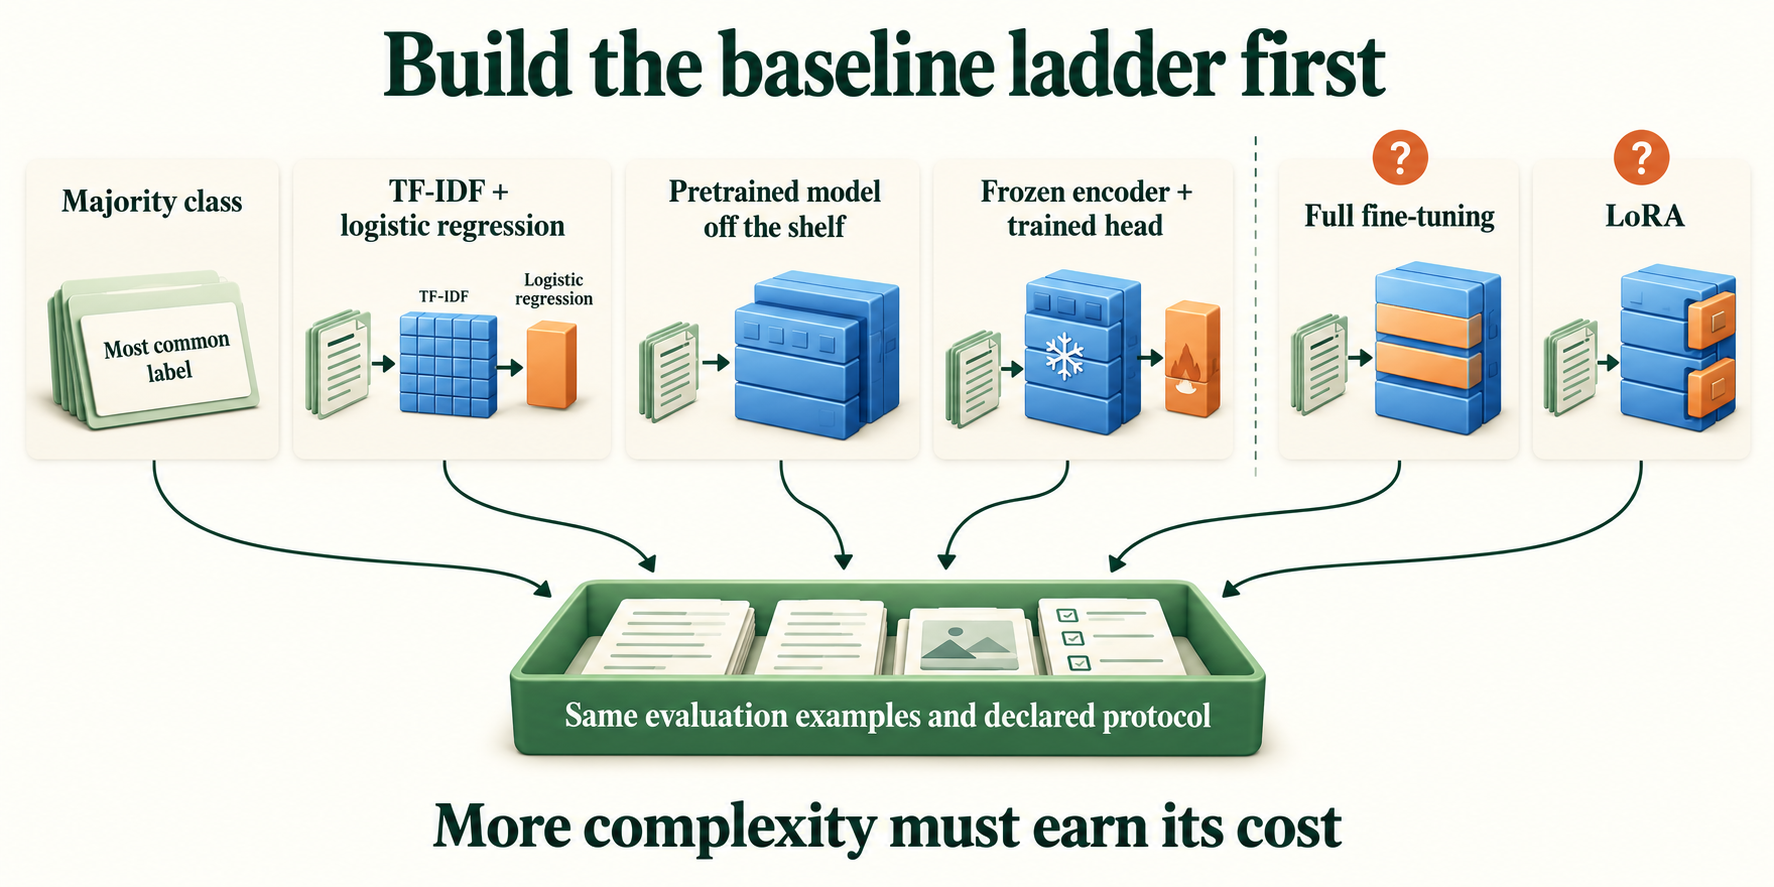

*Figure 8.3.1. Baselines share a declared evaluation protocol. Off-the-shelf, frozen-feature and trained alternatives use different upstream training and sometimes different input information; disclose those differences.*

### The data and the protocol

All rungs use the fixed split (Note 7.1), with fingerprints, and the same subsets: **1,000 training reviews** (the first 1,000 of the training split), the **1,000 `val_eval` reviews** for every choice of setting, and the **1,000 `test_eval` reviews**, used once per rung. We also fingerprint the 1,000 training reviews, so Notes 8.4 and 8.5 can prove they train on the same ones.

In [2]:
def load_imdb_split(seed=0, n_val=2500, n_eval=1000, verbose=True):
    """The fixed IMDb split shared by every note in Modules 7 and 8 (built in Note 7.1)."""
    ds = load_dataset("stanfordnlp/imdb", cache_dir="data/imdb",
                      data_files={"train": "plain_text/train-*.parquet",
                                  "test":  "plain_text/test-*.parquet"}, revision=DATASET_REVISIONS.get("stanfordnlp/imdb"))
    def dedup(texts, labels, seen):
        keep = []
        for i, t in enumerate(texts):
            if t not in seen:                              # keep only the first copy of each review
                seen.add(t); keep.append(i)
        return [texts[i] for i in keep], np.array([labels[i] for i in keep])
    tr_x, tr_y = dedup(list(ds["train"]["text"]), list(ds["train"]["label"]), set())
    te_x, te_y = dedup(list(ds["test"]["text"]), list(ds["test"]["label"]), set(tr_x))  # also drops test reviews already in train
    if verbose:
        print(f"official split: {len(ds['train'])} train, {len(ds['test'])} test reviews")
        print(f"duplicates removed: {len(ds['train']) - len(tr_x)} from train, "
              f"{len(ds['test']) - len(te_x)} from test (repeats, or reviews that are also in train)")
    clean = lambda xs: [x.replace("<br />", " ") for x in xs]                         # remove HTML line breaks
    rng = np.random.default_rng(seed)
    p = rng.permutation(len(tr_x)); v, t = p[:n_val], p[n_val:]                       # validation is carved from train
    q = rng.permutation(len(te_x))[:n_eval]                                           # a fixed sample of the test set
    split = {"train": (clean([tr_x[i] for i in t]), tr_y[t]),
             "val":   (clean([tr_x[i] for i in v]), tr_y[v]),
             "test":  (clean(te_x), te_y)}
    split["val_eval"] = (split["val"][0][:n_eval], split["val"][1][:n_eval])
    split["test_eval"] = (clean([te_x[i] for i in q]), te_y[q])
    return split

def fingerprint(texts):
    """A short ID for a set of texts: identical sets give identical fingerprints."""
    return hashlib.sha256("\n".join(sorted(texts)).encode()).hexdigest()[:12]

In [3]:
imdb = load_imdb_split()
for name, (x, y) in imdb.items():
    print(f"{name:<9} {len(x):>6} reviews | positive share {y.mean():.3f} | fingerprint {fingerprint(x)}")
train_x, train_y = imdb["train"][0][:1000], imdb["train"][1][:1000]     # the 1,000 labelled reviews of Module 8
all_x, all_y = imdb["train"]                                             # every training review, for comparison
val_x, val_y = imdb["val_eval"]                                          # 1,000 validation reviews: for choices
test_x, test_y = imdb["test_eval"]                                       # 1,000 test reviews: used once per rung
print("Module 8 training set fingerprint:", fingerprint(train_x))

official split: 25000 train, 25000 test reviews
duplicates removed: 96 from train, 322 from test (repeats, or reviews that are also in train)
train      22404 reviews | positive share 0.502 | fingerprint fb3a1229f951
val         2500 reviews | positive share 0.492 | fingerprint 07758bc36c9b
test       24678 reviews | positive share 0.503 | fingerprint 429c5557b6d4
val_eval    1000 reviews | positive share 0.495 | fingerprint 9934ffeaac91
test_eval   1000 reviews | positive share 0.515 | fingerprint fc9fa98701bc
Module 8 training set fingerprint: 7b0ca50110ca


We report four numbers for every rung: **accuracy**, **recall** for each class, and **F1** for the positive class (Note 8.2). We start with the floor: always predict the most common label in the 1,000 training reviews.

In [4]:
def metrics(y, p):
    """Accuracy, per-class recall and F1 for the positive class."""
    y, p = np.asarray(y), np.asarray(p)
    tp, fp, fn = ((p == 1) & (y == 1)).sum(), ((p == 1) & (y == 0)).sum(), ((p == 0) & (y == 1)).sum()
    return {"accuracy": round(float((p == y).mean()), 4),
            "recall_neg": round(float(((p == 0) & (y == 0)).sum() / (y == 0).sum()), 4),
            "recall_pos": round(float(tp / (y == 1).sum()), 4),
            "f1_pos": round(float(2 * tp / (2 * tp + fp + fn)), 4)}

results = {}                                                             # everything we measure goes here
majority = int(np.bincount(train_y).argmax())
results["majority class"] = {"val": metrics(val_y, np.full(len(val_y), majority)),
                             "test": metrics(test_y, np.full(len(test_y), majority)), "labels_used": 1000,
                             "test_pred": [majority] * len(test_y)}
print("always predict", "positive" if majority else "negative", "| val", results["majority class"]["val"])

always predict negative | val {'accuracy': 0.505, 'recall_neg': 1.0, 'recall_pos': 0.0, 'f1_pos': 0.0}


The training subset has slightly more negative reviews, so the floor always says negative. It scores 0.505 on validation, chance level, with a recall of 1.0 for negatives and 0.0 for positives. Every rung must clear this comfortably.

## 2. Rung 1: TF-IDF + Logistic Regression

TF-IDF turns each review into a long vector of word weights (Note 7.1). Here we use single words and word pairs (`ngram_range=(1, 2)`), keep only terms that appear in at least two reviews, and dampen very frequent words (`sublinear_tf`). Logistic regression then learns one weight per term. The vectoriser is fitted on the training reviews only, never on validation or test (Note 8.2, Section 7).

One setting needs choosing: `C`, which controls **regularisation**, how strongly large weights are discouraged. Smaller `C` means stronger regularisation. We try four values and choose by validation accuracy, then evaluate the chosen model once on test. We do this twice: with the 1,000 labelled reviews, and with all 22,404 as a reference for what plenty of labels can do.

In [5]:
def tfidf_rung(x, y, C):
    t0 = benchmark_clock()
    vec = TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)   # words and word pairs
    X = vec.fit_transform(x)                                              # fitted on training reviews only
    clf = LogisticRegression(C=C, max_iter=2000).fit(X, y)
    return vec, clf, benchmark_clock() - t0

best_C = {}
for name, (x, y) in {"TF-IDF, 1,000 labels": (train_x, train_y), "TF-IDF, all labels": (all_x, all_y)}.items():
    scores = {}
    for C in (0.3, 1, 3, 10):
        vec, clf, secs = tfidf_rung(x, y, C)
        scores[C] = (clf.predict(vec.transform(val_x)) == val_y).mean()      # choose C on validation
    print(f"{name}: validation accuracy by C:", {c: round(float(v), 3) for c, v in scores.items()})
    best_C[name] = max(scores, key=scores.get)
    vec, clf, secs = tfidf_rung(x, y, best_C[name])
    results[name] = {"val": metrics(val_y, clf.predict(vec.transform(val_x))),
                     "test": metrics(test_y, clf.predict(vec.transform(test_x))),
                     "test_pred": clf.predict(vec.transform(test_x)).tolist(),
                     "labels_used": len(y), "trained_parameters": int(clf.coef_.size + 1),
                     "train_time": f"{secs:.1f} s", "setting": f"C={best_C[name]}"}
    print(f"{name:<22} C={best_C[name]:<4} vocabulary {clf.coef_.size:>9,} | val {results[name]['val']['accuracy']:.3f} | "
          f"test {results[name]['test']['accuracy']:.3f} | fit in {secs:.1f} s")

TF-IDF, 1,000 labels: validation accuracy by C: {0.3: 0.851, 1: 0.862, 3: 0.866, 10: 0.863}


TF-IDF, 1,000 labels   C=3    vocabulary    29,754 | val 0.866 | test 0.828 | fit in 0.1 s


TF-IDF, all labels: validation accuracy by C: {0.3: 0.891, 1: 0.91, 3: 0.916, 10: 0.921}


TF-IDF, all labels     C=10   vocabulary   399,450 | val 0.921 | test 0.913 | fit in 4.2 s


With 1,000 labels, the best setting is C=3, with validation accuracy 0.866 and test accuracy 0.828. Note the gap between validation and test. Part of it is that we *chose* C on validation, so the chosen value is a little lucky there; part is ordinary sampling noise on 1,000 reviews. It's a reminder that the test number is the one to report.

With all 22,404 labels, TF-IDF reaches 0.921 on validation and 0.913 on test. Its vocabulary grows from 29,754 terms to 399,450, and the best C, 10, is the largest we tried, so even weaker regularisation might do slightly better. More data supports a more complex model. Fitting took a fraction of a second with 1,000 reviews, and a few seconds with all of them.

> **Key terms**
> - **Baseline:** a simple reference method, evaluated exactly like the method you hope will beat it.
> - **Regularisation:** a penalty that discourages large weights, reducing overfitting; in scikit-learn's logistic regression, smaller `C` means stronger regularisation.
> - **n-grams:** sequences of n consecutive words; `(1, 2)` means single words and word pairs.

**Check yourself.**

1. Why must the TF-IDF vectoriser be fitted on training reviews only? What would leak if it were fitted on all reviews, including test?

<details>
<summary>Worked answer</summary>

The vectoriser learns which terms exist and how common they are (the IDF weights). Fitted on all reviews, it would learn from the test reviews: terms that appear only in test reviews would get a place in the vocabulary, and the IDF weights would reflect test-set frequencies. The model would then be built partly from test data, so its test score would no longer be an honest estimate for unseen reviews.

</details>

## 3. Rung 2: A Pretrained Model Off the Shelf

The second rung uses no IMDb labels at all: the SST-2 sentiment model from Module 7, exactly as downloaded. It's the baseline every adaptation must clearly beat, because it costs nothing to train. We feed it the same head+tail 128-token inputs the fine-tuned models will use (Note 8.2).

The helpers below are shared with rung 3: `head_tail` builds the 128-token inputs, and `batches` groups reviews of similar length to cut padding (Note 7.4).

In [6]:
SST2 = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
tok = AutoTokenizer.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2))            # DistilBERT's vocabulary; also used by rung 3

def head_tail(texts, max_length=128):
    """Keep the first quarter and last three quarters of the token budget (built in Note 8.2)."""
    keep = max_length - 2
    rows = []
    for ids in tok(texts, add_special_tokens=False)["input_ids"]:
        if len(ids) > keep:
            ids = ids[:keep // 4] + ids[-(keep - keep // 4):]
        rows.append([tok.cls_token_id] + ids + [tok.sep_token_id])
    n = max(len(r) for r in rows)
    input_ids = torch.tensor([r + [tok.pad_token_id] * (n - len(r)) for r in rows])
    return {"input_ids": input_ids, "attention_mask": (input_ids != tok.pad_token_id).long()}

def batches(texts, size=32):
    order = np.argsort([len(t) for t in texts])                           # similar lengths together (Note 7.4)
    for i in range(0, len(texts), size):
        idx = order[i:i + size]
        yield idx, {k: v.to(device) for k, v in head_tail([texts[j] for j in idx]).items()}

In [7]:
sst2 = AutoModelForSequenceClassification.from_pretrained(SST2, revision=MODEL_REVISIONS.get(SST2)).to(device).eval()
def sst2_predict(texts):
    pred = np.empty(len(texts), dtype=int)
    with torch.inference_mode():
        for idx, enc in batches(texts):
            pred[idx] = sst2(**enc).logits.argmax(-1).cpu().numpy()
    return pred

t0 = benchmark_clock()
val_pred = sst2_predict(val_x)
ms = (benchmark_clock() - t0) / len(val_x) * 1000
test_pred = sst2_predict(test_x)
results["SST-2 model, off the shelf"] = {"val": metrics(val_y, val_pred), "test": metrics(test_y, test_pred),
                                         "test_pred": test_pred.tolist(), "labels_used": 0, "trained_parameters": 0,
                                         "inference": f"{ms:.1f} ms per review", "setting": "head+tail, 128 tokens"}
print(f"val {results['SST-2 model, off the shelf']['val']['accuracy']:.3f} | test {results['SST-2 model, off the shelf']['test']['accuracy']:.3f} | {ms:.1f} ms per review")
del sst2

W1017 19:40:50.040000 86498 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1017 19:40:50.130000 86498 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1017 19:40:50.149000 86498 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 11478.85it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (526 > 512). Running this sequence through the model will result in indexing errors


val 0.888 | test 0.873 | 9.9 ms per review


The off-the-shelf model scores 0.888 on validation and 0.873 on test, without seeing a single IMDb label. Its time per review is printed above; it depends on your processor, so compare it only with other timings from your own run. The bar for any adapted model trained on 1,000 IMDb reviews is therefore already high: someone else's adaptation, on a related task, is free.

## 4. Rung 3: A Frozen Encoder with a Trained Linear Head

The third rung is **feature extraction** (Note 8.1): DistilBERT's pretrained body stays frozen, mean-pooled into one 768-number vector per review, and a logistic-regression head is trained on the same 1,000 labelled reviews. This is exactly a fine-tuned model *minus* the fine-tuning: same encoder, same inputs, same labels, but the encoder never changes. Comparing it with Notes 8.4 and 8.5 will show what adapting the encoder itself adds.

In [8]:
BASE = "distilbert/distilbert-base-uncased"
encoder = AutoModel.from_pretrained(BASE, revision=MODEL_REVISIONS.get(BASE)).to(device).eval()              # frozen: we never update it
def features(texts):
    out = np.empty((len(texts), encoder.config.dim), dtype=np.float32)
    with torch.inference_mode():
        for idx, enc in batches(texts):
            h = encoder(**enc).last_hidden_state                          # (B, T, 768)
            m = enc["attention_mask"].unsqueeze(-1).float()
            out[idx] = ((h * m).sum(1) / m.sum(1)).cpu().numpy()          # mean over real tokens
    return out

t0 = benchmark_clock()
F_train = features(train_x)
feat_secs = benchmark_clock() - t0
F_val, F_test = features(val_x), features(test_x)
print("features:", F_train.shape, F_val.shape, F_test.shape, f"| training features took {feat_secs:.1f} s")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 7341.04it/s]


[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


features: (1000, 768) (1000, 768) (1000, 768) | training features took 9.9 s


Each review becomes a vector of 768 features. Computing them for the training reviews takes a few seconds, and that one pass is the only use of the Transformer during training. Now we choose the head's regularisation on validation:

In [9]:
scores = {}
for C in (0.01, 0.1, 1, 10):                                             # choose regularisation on validation
    probe = LogisticRegression(C=C, max_iter=5000).fit(F_train, train_y)
    scores[C] = (probe.predict(F_val) == val_y).mean()
    print(f"C={C:<5} validation accuracy {scores[C]:.3f}")
C = max(scores, key=scores.get)
t0 = benchmark_clock()
probe = LogisticRegression(C=C, max_iter=5000).fit(F_train, train_y)
fit_secs = benchmark_clock() - t0
results["frozen DistilBERT + logistic regression"] = {
    "val": metrics(val_y, probe.predict(F_val)), "test": metrics(test_y, probe.predict(F_test)),
    "test_pred": probe.predict(F_test).tolist(), "labels_used": 1000, "trained_parameters": int(probe.coef_.size + 1),
    "train_time": f"{feat_secs + fit_secs:.1f} s", "setting": f"mean pooling, head+tail 128, C={C}"}
r = results["frozen DistilBERT + logistic regression"]
print(f"chosen C={C} | val {r['val']['accuracy']:.3f} | test {r['test']['accuracy']:.3f} | trained parameters {r['trained_parameters']}")

C=0.01  validation accuracy 0.815
C=0.1   validation accuracy 0.841
C=1     validation accuracy 0.850
C=10    validation accuracy 0.841
chosen C=1 | val 0.850 | test 0.837 | trained parameters 769


The best setting, C=1, gives 0.850 on validation and 0.837 on test. The trained part is tiny: 769 parameters (768 weights and a bias). Everything else comes from pretraining.

> **Key terms**
> - **Frozen encoder:** a pretrained model used only to compute features, never updated.
> - **Linear head (linear probe):** a single linear layer, here logistic regression, trained on frozen features.

**Check yourself.**

1. Rung 3 uses the same encoder, inputs and labels as full fine-tuning will in Note 8.4. If fine-tuning then scores clearly higher, what does that tell you?

<details>
<summary>Worked answer</summary>

That adapting the encoder's own weights matters for this task. Everything else (encoder, inputs, labels) is the same as rung 3, so a clear gain must come from letting the encoder change its representations to suit IMDb sentiment, rather than reading a fixed representation with a linear head. A sign test on the same test reviews would confirm whether the gain is real.

</details>

## 5. Setting the Evaluation Protocol: Metrics, Fixed Split, Timing

### 5.1 All rungs side by side

Here is every rung on the same 1,000 validation and 1,000 test reviews:

In [10]:
print(f"{'rung':<40} {'labels':>7} {'val acc':>8} {'test acc':>9} {'recall neg':>11} {'recall pos':>11} {'F1 pos':>7}")
for name, r in results.items():
    t = r["test"]
    print(f"{name:<40} {r['labels_used']:>7,} {r['val']['accuracy']:>8.3f} {t['accuracy']:>9.3f} {t['recall_neg']:>11.3f} {t['recall_pos']:>11.3f} {t['f1_pos']:>7.3f}")

rung                                      labels  val acc  test acc  recall neg  recall pos  F1 pos
majority class                             1,000    0.505     0.485       1.000       0.000   0.000
TF-IDF, 1,000 labels                       1,000    0.866     0.828       0.821       0.835   0.833
TF-IDF, all labels                        22,404    0.921     0.913       0.920       0.907   0.915
SST-2 model, off the shelf                     0    0.888     0.873       0.856       0.889   0.878
frozen DistilBERT + logistic regression    1,000    0.850     0.837       0.835       0.839   0.841


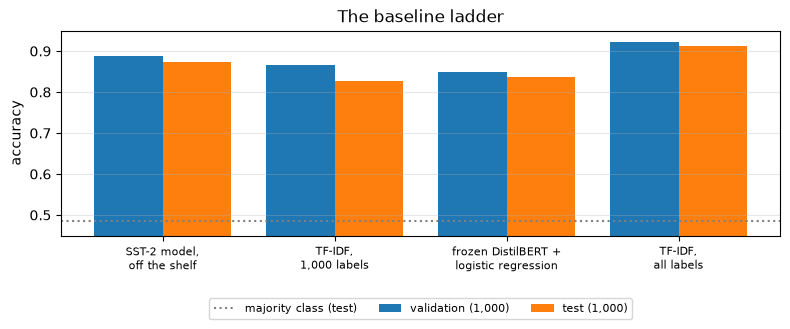

In [11]:
names = ["SST-2 model, off the shelf", "TF-IDF, 1,000 labels", "frozen DistilBERT + logistic regression", "TF-IDF, all labels"]
fig, ax = plt.subplots(figsize=(8, 3.6))
xs = np.arange(len(names))
ax.bar(xs - 0.2, [results[n]["val"]["accuracy"] for n in names], 0.4, label="validation (1,000)")
ax.bar(xs + 0.2, [results[n]["test"]["accuracy"] for n in names], 0.4, label="test (1,000)")
ax.axhline(results["majority class"]["test"]["accuracy"], color="grey", ls=":", label="majority class (test)")
ax.set_xticks(xs); ax.set_xticklabels([n.replace(", ", ",\n").replace(" + ", " +\n") for n in names], fontsize=8)
ax.set_ylim(0.45, 0.95); ax.set_ylabel("accuracy"); ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3)
ax.set_title("The baseline ladder"); plt.tight_layout(); plt.show()

Reading the ladder, from the test column:
- **Every rung clears the floor (0.485) by a wide margin,** and all have balanced recall on the two classes, so none is succeeding by favouring one label.
- **Rung 2, the off-the-shelf SST-2 model, is the strongest method that uses 1,000 labels or fewer,** at 0.873 with *no* IMDb labels.
- **With 1,000 labels, TF-IDF (0.828) and the frozen encoder (0.837) are close,** and both below the off-the-shelf model.
- **TF-IDF with all 22,404 labels is the strongest of all (0.913).** Plenty of labels make even a simple model hard to beat.

### 5.2 Are the differences real?

Differences of a few points on 1,000 reviews can be noise, so we test the important ones with the sign test on **paired** predictions: the same test reviews, comparing which model gets each one right (Module 5). With 1,000 test reviews, one review is worth 0.1 percentage points.

In [12]:
def sign_test(a, b, y):
    a_right, b_right = np.asarray(a) == y, np.asarray(b) == y
    only_a, only_b = int((a_right & ~b_right).sum()), int((~a_right & b_right).sum())
    return only_a, only_b, (binomtest(only_a, only_a + only_b).pvalue if only_a + only_b else 1.0)

print(f"test set: {len(test_y)} reviews, one review = {1 / len(test_y):.1%}")
for a, b in [("SST-2 model, off the shelf", "TF-IDF, 1,000 labels"),
             ("frozen DistilBERT + logistic regression", "TF-IDF, 1,000 labels"),
             ("TF-IDF, all labels", "SST-2 model, off the shelf")]:
    oa, ob, p = sign_test(results[a]["test_pred"], results[b]["test_pred"], test_y)
    print(f"{a} vs {b}: only first right {oa} | only second right {ob} | p = {p:.2g}")

test set: 1000 reviews, one review = 0.1%
SST-2 model, off the shelf vs TF-IDF, 1,000 labels: only first right 126 | only second right 81 | p = 0.0022
frozen DistilBERT + logistic regression vs TF-IDF, 1,000 labels: only first right 98 | only second right 89 | p = 0.56
TF-IDF, all labels vs SST-2 model, off the shelf: only first right 96 | only second right 56 | p = 0.0015


- **The off-the-shelf model beats TF-IDF with 1,000 labels:** it is right on 126 reviews where TF-IDF is wrong, and wrong on only 81 where TF-IDF is right (p = 0.0022).
- **The frozen encoder and TF-IDF, both with 1,000 labels, are not reliably different** (98 against 89, p = 0.56).
- **TF-IDF with all labels beats the off-the-shelf model** (96 against 56, p = 0.0015).

So the honest summary of the baselines: with 1,000 labels, the bar to beat is the off-the-shelf model at 0.873, and with all labels, TF-IDF at 0.913.

### 5.3 What the protocol fixes

Everything Notes 8.4–8.7 compare will follow the same protocol:
- **Fixed data:** the same split, checked by fingerprint, and the same 1,000 training, 1,000 validation and 1,000 test reviews.
- **Choices on validation only:** regularisation strength, learning rates, epochs, checkpoints.
- **Test once per method,** after all choices are made.
- **The same metrics:** accuracy, per-class recall and F1, plus paired sign tests for comparisons.
- **Costs recorded alongside quality:** labels used, parameters trained, and training and inference time (timings printed with units; they vary between machines and runs, so compare them within one run, not across machines).

### 5.4 Saving the results

To let Note 8.7 compare every rung on the same test reviews without retraining anything, we save the results, including each rung's prediction for every test review, to a file. Notes 8.4 and 8.5 will save theirs the same way.

In [13]:
os.makedirs("results", exist_ok=True)
record = {"note": "8.3", "split_fingerprints": {k: fingerprint(imdb[k][0]) for k in ("train", "val_eval", "test_eval")},
          "train_subset_fingerprint": fingerprint(train_x), "rungs": results}
record['ordered_test_fingerprint'] = ordered_fingerprint(test_x, test_y)
record['artifact_origin'] = 'learner execution of this notebook'
record['model_revisions'] = MODEL_REVISIONS
record['dataset_revisions'] = DATASET_REVISIONS
with open("results/8.3.json", "w") as f:
    json.dump(record, f, indent=1)
print("wrote results/8.3.json |", len(results), "rungs |", os.path.getsize("results/8.3.json") // 1000, "kB")

wrote results/8.3.json | 5 rungs | 37 kB


The file records the split fingerprints, the training-subset fingerprint and, for each rung, its metrics, settings, costs and test predictions. If Note 8.7 finds a fingerprint that doesn't match, it will refuse to compare, rather than compare different reviews by mistake.

> **Key terms**
> - **Evaluation protocol:** the fixed rules for how every method is measured: data, metrics, when the test set is used, and how results are compared.
> - **Paired comparison:** comparing two methods on the same examples, example by example.
> - **Results file:** a saved record of a method's settings, costs, metrics and predictions, for later comparison.

> **Common mistake:** comparing your fine-tuned model with a *weak* baseline, or with one evaluated on different data. Beating "always negative" or a poorly tuned TF-IDF proves little. Tune each baseline on validation as carefully as the model you hope will beat it, and evaluate everything on the same reviews.

**Check yourself.**

1. A colleague reports that their fine-tuned model scored 0.86 on test, against 0.83 for TF-IDF, but the TF-IDF number came from a different random test split. Why can't you conclude anything yet?

<details>
<summary>Worked answer</summary>

The two numbers come from different test reviews, so the difference could be due entirely to which reviews landed in each test set, not to the methods. A fair comparison needs both methods on the same test reviews (ideally with a paired test), with the same training data and the same rules for choosing settings.

</details>

## Putting It All Together

Let's reassemble the baseline ladder.

A **baseline** sets the bar an adapted model must clear, catches mistakes, and shows where gains come from. Our ladder, on the same fixed reviews with fingerprints, tuned on 1,000 validation reviews and tested once on 1,000 test reviews:

| Rung | Labels | Validation | Test | Trained parameters |
|---|---|---|---|---|
| floor: always negative | — | 0.505 | 0.485 | 0 |
| 1: TF-IDF + logistic regression | 1,000 | 0.866 | 0.828 | one per term (29,754 terms) |
| 2: SST-2 model, off the shelf | 0 | 0.888 | 0.873 | 0 |
| 3: frozen DistilBERT + logistic regression | 1,000 | 0.850 | 0.837 | 769 |
| reference: TF-IDF + logistic regression | 22,404 | 0.921 | 0.913 | one per term (399,450 terms) |

Paired sign tests showed that the off-the-shelf model beats both 1,000-label baselines (p = 0.0022 against TF-IDF), that the frozen encoder and TF-IDF are not significantly different in this paired comparison at 1,000 labels (p = 0.56), and that TF-IDF with all labels beats everything (p = 0.0015 against the off-the-shelf model). The **protocol** (fixed data, choices on validation, test once, the same metrics, costs recorded) is saved with every result in `results/8.3.json`.

For fine-tuning on 1,000 reviews in Notes 8.4 and 8.5, the bar is clear: beat 0.873, the free off-the-shelf model, and know that 0.913 is what plenty of labels and a simple model achieve.

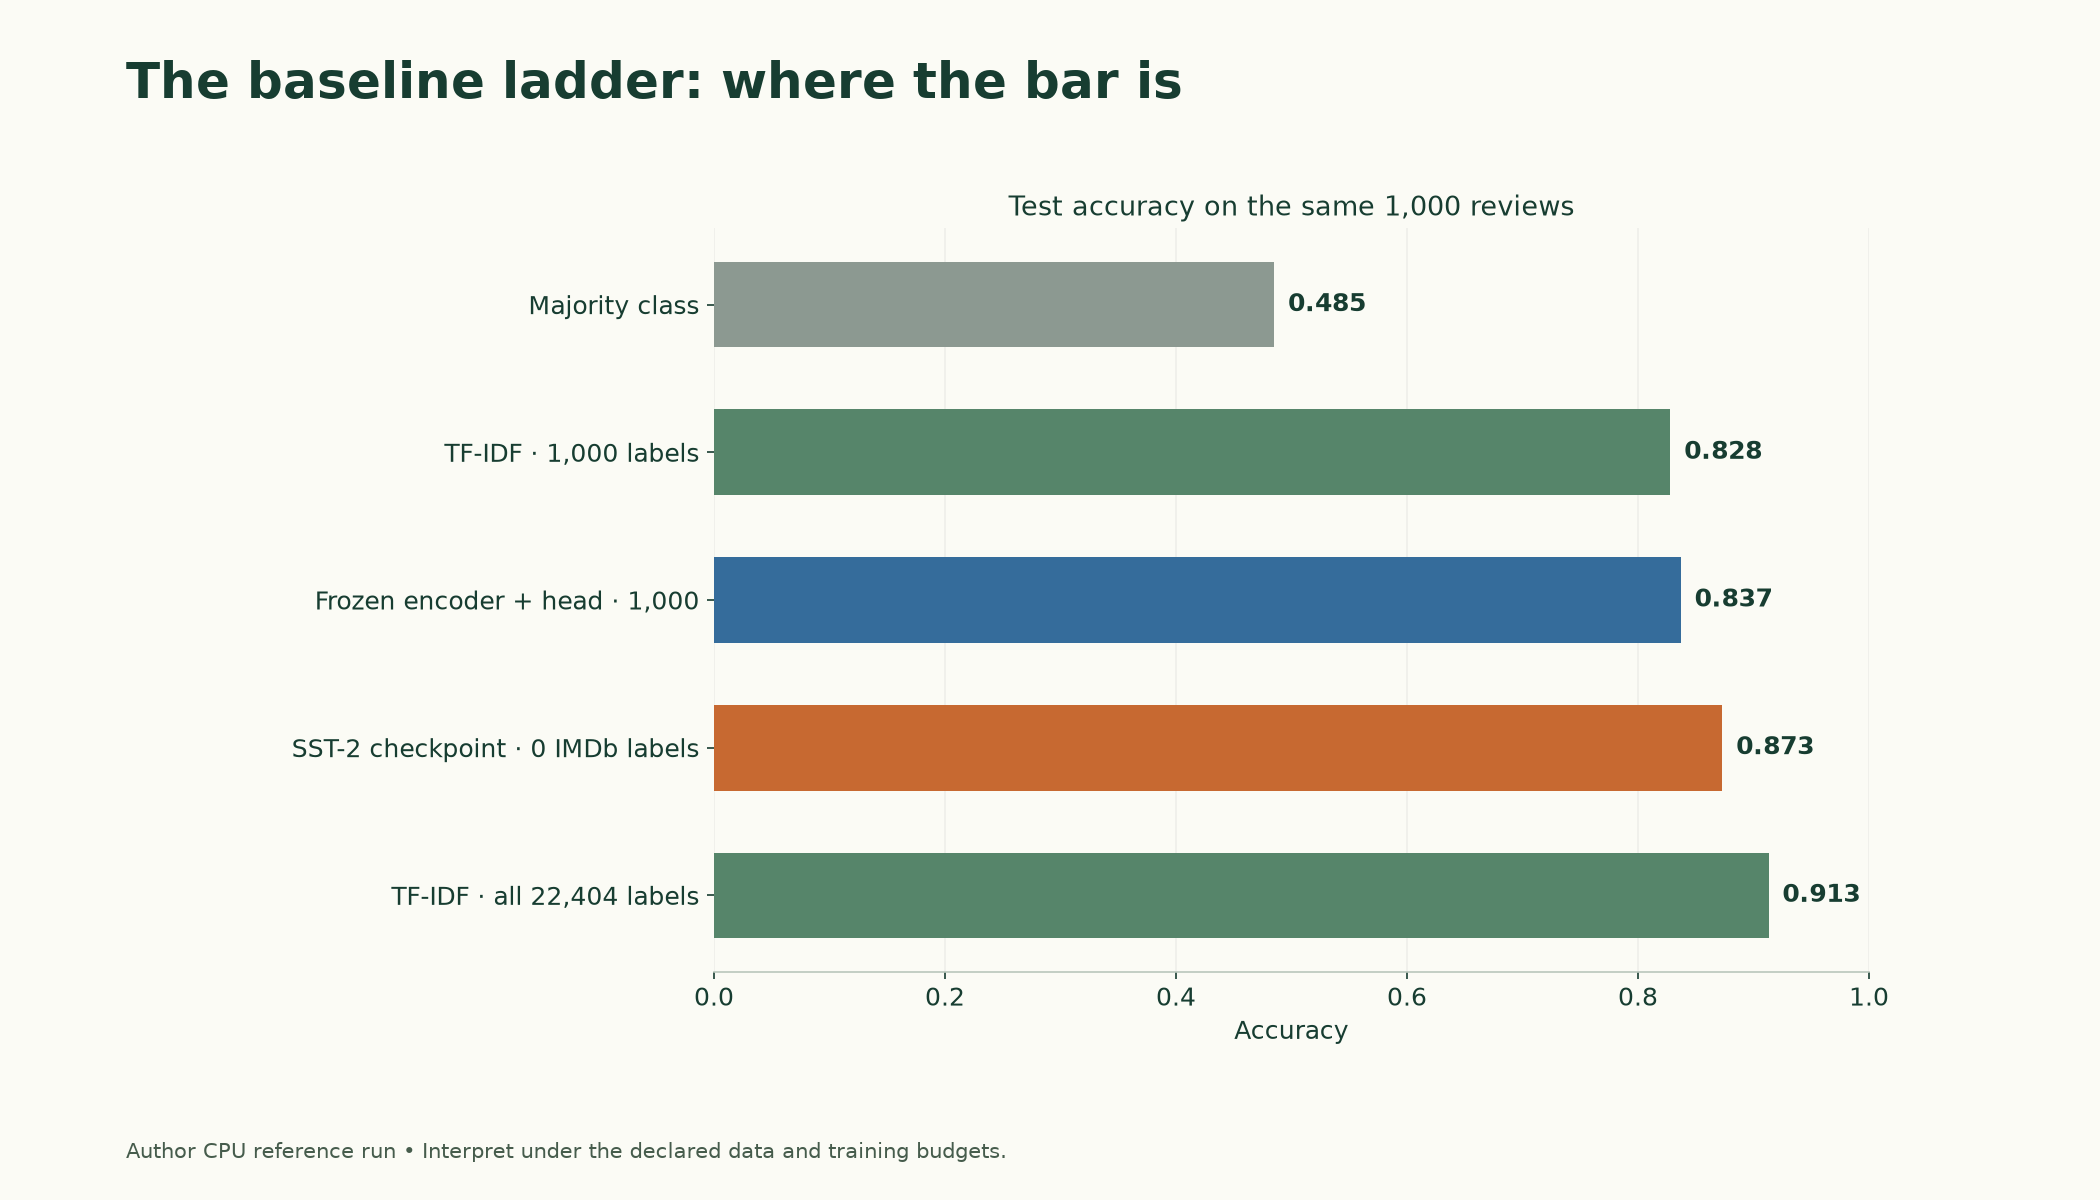

*Figure 8.3.2. Source test accuracy on 1,000 reviews, with training-label budgets shown. All-label TF-IDF is a separate reference budget; it reads the full text rather than 128 Transformer tokens.*

## Summary

- A **baseline** is a simple method evaluated exactly like the method you hope will beat it; it sets the bar, catches mistakes and shows where gains come from.
- The **baseline ladder** used the same 1,000 training, 1,000 validation and 1,000 test reviews (fingerprinted) for every rung.
- **Rung 1, TF-IDF + logistic regression,** tuned on validation: 0.828 on test with 1,000 labels; 0.913 with all 22,404.
- **Rung 2, the SST-2 model off the shelf** (head+tail, 128 tokens): 0.873 on test with no IMDb labels.
- **Rung 3, frozen DistilBERT + logistic regression** (769 trained parameters): 0.837 on test with 1,000 labels.
- **Paired sign tests:** off the shelf beats TF-IDF at 1,000 labels (p = 0.0022); frozen features and TF-IDF are not significantly different in this paired comparison (p = 0.56); TF-IDF with all labels beats off the shelf (p = 0.0015).
- **The protocol:** fixed data, choices on validation only, test once per method, the same metrics, costs recorded. Results and test predictions are saved to `results/8.3.json` for Note 8.7.

## Glossary

| Term | Meaning |
|---|---|
| Baseline | A simple reference method evaluated exactly like the method under test. |
| Baseline ladder | A set of baselines of increasing sophistication, measured identically. |
| Majority-class floor | A constant-label baseline selected from training data and evaluated under the same protocol; it is not a guaranteed lower bound. |
| TF-IDF | Word-count features down-weighting words common to most documents (Note 7.1). |
| n-gram | A sequence of n consecutive words. |
| Regularisation | A penalty discouraging large weights; smaller `C` means stronger regularisation. |
| Off-the-shelf model | A pretrained model used exactly as downloaded, with no further training. |
| Feature extraction | Using a frozen model's outputs as features for a separate classifier. |
| Frozen encoder | A pretrained model whose parameters stay fixed during the current training stage. |
| Linear head (probe) | A single linear layer trained on frozen features. |
| Evaluation protocol | Fixed rules for how every method is measured and compared. |
| Paired comparison | Comparing two methods on the same examples, example by example. |
| Sign test | A paired test counting the examples where exactly one of two methods is right. |
| Results file | A saved record of a method's settings, costs, metrics and predictions. |